# Development tournament: which configuration to freeze?

**Which OR-Tools (Perron & Furnon, 2026) configuration should be frozen, chosen only on development instances and under a pre-registered rule?** This notebook reads results that were already produced and frozen (`outputs/frozen/`); no solver is run here.

**Pre-registered protocol (Nosek et al., 2018)** (`reports/protocolo-grade-dev.md`, registered before any execution of the grid):

- 18 configurations = 2 fleet strategies (`fixed_cost`: a single solve with a fixed cost per vehicle; `reduce_fleet`: a loop that re-solves with one vehicle fewer) × 3 first solutions (`PARALLEL_CHEAPEST_INSERTION`, `PATH_CHEAPEST_ARC`, `SAVINGS`) × 3 metaheuristics (`GUIDED_LOCAL_SEARCH`, `TABU_SEARCH`, `SIMULATED_ANNEALING`), where `SAVINGS` is the savings heuristic (Clarke & Wright, 1964), `GUIDED_LOCAL_SEARCH` is guided local search (Voudouris & Tsang, 1999), `TABU_SEARCH` is tabu search (Glover, 1986) and `SIMULATED_ANNEALING` is simulated annealing (Kirkpatrick et al., 1983) (overview of metaheuristics for the VRPTW: Bräysy & Gendreau, 2005b);
- 14 development instances, a total wall-clock budget of 30 s per run, one replicate per cell (Barr et al., 1995);
- **selection rule:** on each instance the 18 configurations are ordered by (feasible, fewer vehicles, shorter distance); the one with the lowest mean rank wins; ties are broken by the lower mean Δ vehicles and then by the lower median distance gap among instances whose fleet equals the reference;
- the winner is frozen in `outputs/frozen/selected_config.json` and is the only one taken to the evaluation on the remaining 42 instances.

**Anti-leakage design (Kaufman et al., 2012):** the protocol was registered before the run; only `dev` instances were read; this project's loaders reject any evaluation instance; and the results used here are frozen copies, not the working folders. Section 9 adds the v2 diagnostics (Phase B, `reports/protocolo-v2.md`), registered after the tournament and also on development instances only; they audit the configuration and do not change the tournament selection.

## 1. Environment setup

In this section the development instances, the frozen grid, the ranking and the selected configuration are loaded. The table shows the frozen configuration and the statistics that placed it first.

In [1]:
LANG = "en"  # "pt" or "en"

import matplotlib.pyplot as plt
from IPython.display import display

from delivery_routing_vrptw import analysis, benchmark, eda, paths, results, v2_view, viz_results
from delivery_routing_vrptw.viz import setup_notebook_figures

setup_notebook_figures()

P = paths.data_paths()
R = paths.result_paths()
split = benchmark.read_split(P["split"])
instances, sintef = results.load_dev_instances(P["sintef_zip"], P["sintef_bks"], split)
grid = results.load_dev_grid(R["dev_grid"], split)
ranking = results.load_ranking(R["ranking"])
selected = results.load_selected_config(R["selected_config"], split)
config = selected["config"]

display(eda.localize_columns(analysis.selected_config_table(selected, LANG), LANG))

,Indicator,Value
0,Fleet strategy,fixed_cost
1,First solution,SAVINGS
2,Metaheuristic,GUIDED_LOCAL_SEARCH
3,Mean rank,5.607
4,Mean Δ vehicles,0.857
5,Instances with fleet equal to reference,5
6,"Median gap, equal fleet (%)",1.529
7,Mean runtime (s),30.0
8,No. of instances,14


**Insight.** The frozen configuration is `fixed_cost` + `SAVINGS` + `GUIDED_LOCAL_SEARCH`, with mean rank 5.607 over the 14 instances, mean Δ vehicles 0.857, a fleet equal to the reference on 5 of the 14 instances, a median distance gap of 1.529% on those 5 and a mean runtime of 30.0 s per run (the budget). These values come from the `selected_config.json` file, produced by the pre-registered rule before this notebook. **Limitation:** the file records the selection, not its robustness; that is examined in the following sections. **Next decision:** check that the grid is complete before interpreting the ranking.

## 2. Coverage and feasibility of the grid

**Question:** is the grid complete and are all solutions feasible? **What the table shows:** counts computed from the frozen file: total cells, tournament cells (configurations × instances), reference cells (OR-Tools constructions without local search and own constructive heuristics), instances outside the development set and cells that are feasible under the double-precision verifier.

In [2]:
display(eda.localize_columns(analysis.grid_coverage(grid, split, LANG), LANG))

,Indicator,Value
0,Cells in the grid (total),322
1,Tournament cells (configurations × instances),252
2,Reference cells: OR-Tools construction without...,42
3,Reference cells: own constructive heuristics,28
4,Distinct configurations in the tournament,18
5,Distinct instances,14
6,Instances outside the development set,0
7,Cells feasible under the verifier,322
8,Cells with partial solver status,42
9,"Of which, construction without local search",42


**Insight.** The grid has 322 cells: 252 from the tournament (18 configurations × 14 instances), 42 OR-Tools constructions without local search (3 × 14) and 28 from the own constructive heuristics (2 × 14). There are 14 distinct instances, none outside the development set, and all 322 cells are feasible under the double-precision verifier; hence no configuration was penalised for infeasibility in the selection rule. The 42 cells with partial solver status coincide exactly with the 42 constructions without local search (the other OR-Tools cells have a success status). **Limitation:** complete feasibility shows that the verifier rejected no solution, not that the solutions are good. **Next decision:** read the ranking.

## 3. Ranking of the 18 configurations

**Question:** how do the configurations order under the pre-registered rule? **What is shown:** the ranking table (mean rank over the 14 instances; lower is better) with mean Δ vehicles, number of instances whose fleet equals the reference, median distance gap on those instances and mean runtime; and a heat map of the mean rank by first solution (rows) and metaheuristic (columns), one panel per fleet strategy and a common colour scale.

,Position,Fleet strategy,First solution,Metaheuristic,Mean rank,Mean Δ vehicles,Instances with fleet equal to reference,"Median gap, equal fleet (%)",Mean runtime (s)
0,1,fixed_cost,SAVINGS,GUIDED_LOCAL_SEARCH,5.607,0.857,5,1.529,30.0
1,2,fixed_cost,SAVINGS,TABU_SEARCH,5.893,0.786,6,1.778,26.9
2,3,fixed_cost,PARALLEL_CHEAPEST_INSERTION,GUIDED_LOCAL_SEARCH,6.393,0.929,5,1.529,30.0
3,4,fixed_cost,PATH_CHEAPEST_ARC,GUIDED_LOCAL_SEARCH,7.143,1.000,5,0.001,30.0
4,5,fixed_cost,PATH_CHEAPEST_ARC,TABU_SEARCH,7.357,0.857,5,0.904,22.7
5,6,fixed_cost,PARALLEL_CHEAPEST_INSERTION,TABU_SEARCH,8.036,0.929,5,1.529,26.6
6,7,reduce_fleet,SAVINGS,TABU_SEARCH,8.821,0.857,6,3.594,10.1
7,8,fixed_cost,SAVINGS,SIMULATED_ANNEALING,9.143,1.000,5,2.771,30.0
8,9,reduce_fleet,SAVINGS,GUIDED_LOCAL_SEARCH,9.179,1.000,5,1.529,10.7
9,10,reduce_fleet,PATH_CHEAPEST_ARC,TABU_SEARCH,9.643,0.929,5,0.904,14.0


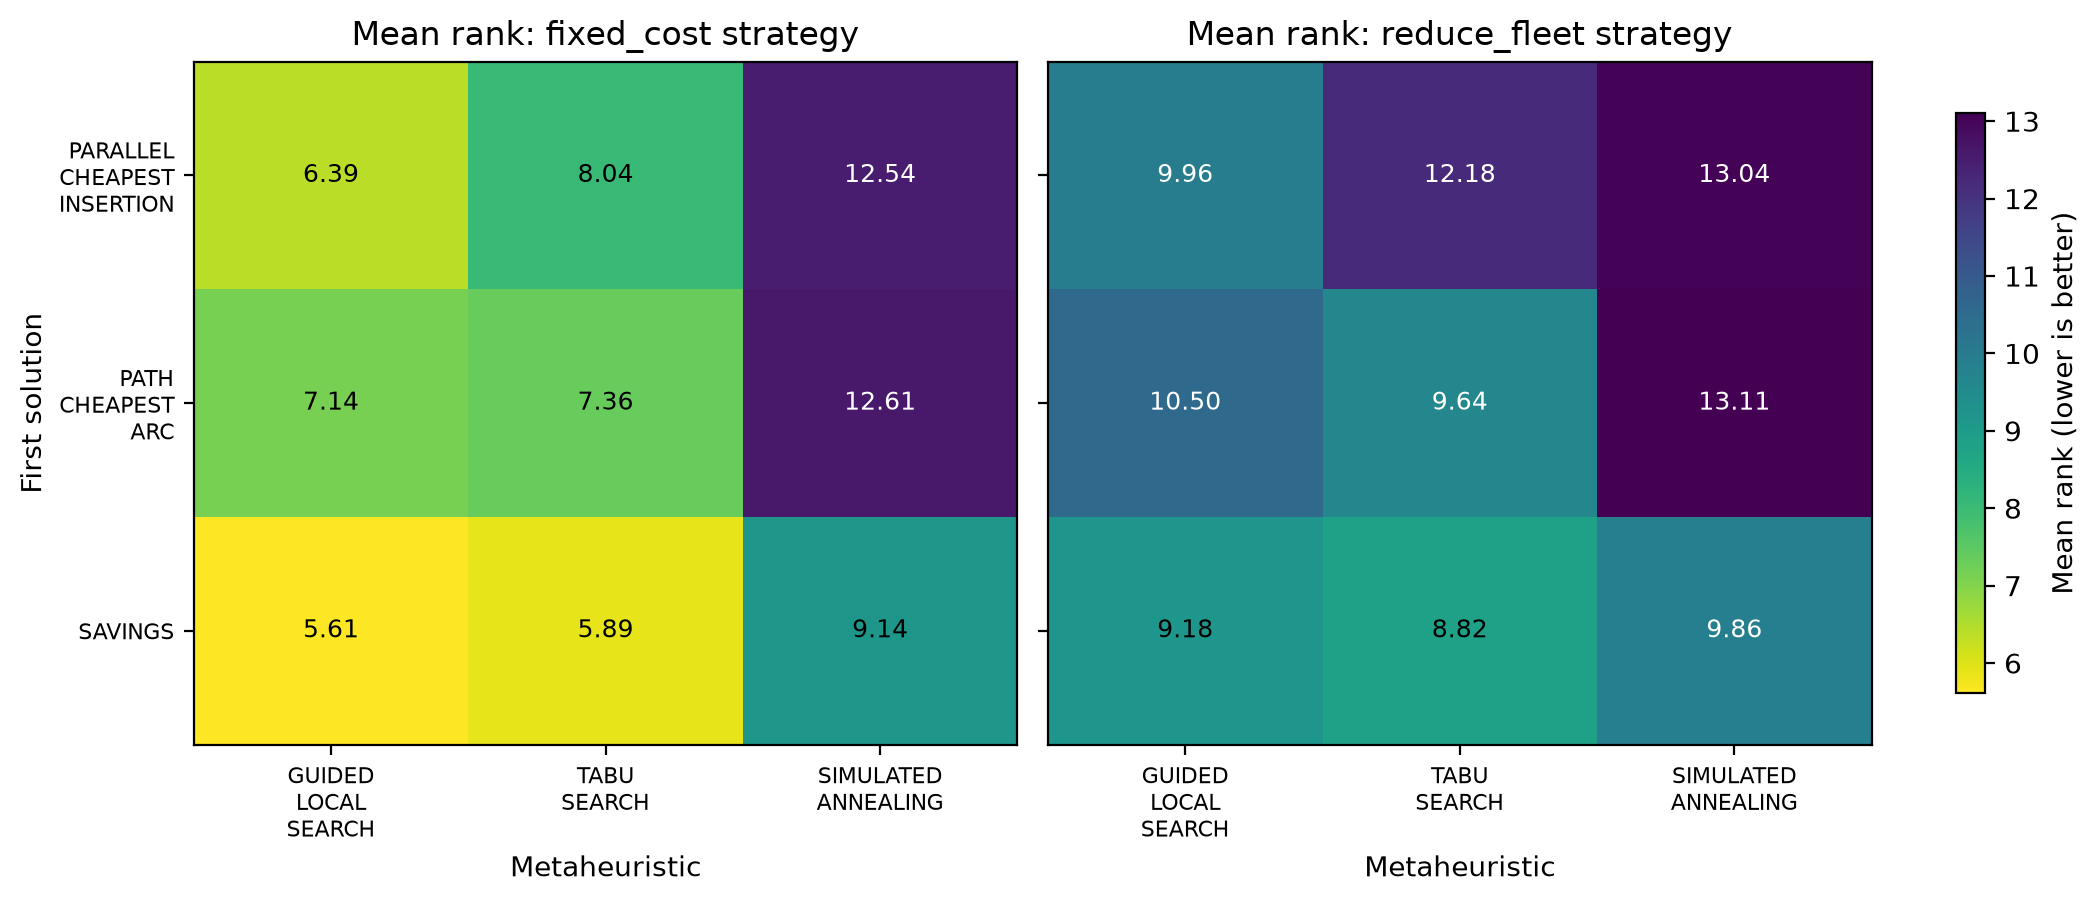

In [3]:
display(eda.localize_columns(analysis.ranking_table(ranking), LANG))

viz_results.plot_rank_heatmap(ranking, LANG)
plt.show()

**Insight.** The first six positions all belong to the `fixed_cost` strategy: `SAVINGS`/`GUIDED_LOCAL_SEARCH` (5.607), `SAVINGS`/`TABU_SEARCH` (5.893), `PARALLEL_CHEAPEST_INSERTION`/`GUIDED_LOCAL_SEARCH` (6.393), `PATH_CHEAPEST_ARC`/`GUIDED_LOCAL_SEARCH` (7.143), `PATH_CHEAPEST_ARC`/`TABU_SEARCH` (7.357) and `PARALLEL_CHEAPEST_INSERTION`/`TABU_SEARCH` (8.036). `SIMULATED_ANNEALING` takes the last four positions (12.536 to 13.107) and, with `SAVINGS`, the 8th and 11th (9.143 and 9.857). In the heat map, `SAVINGS` has the lowest mean rank in each of the six columns (fleet strategy × metaheuristic). The gap between first and second place is 0.286 rank; the second has a lower mean Δ vehicles (0.786 against 0.857) and one more instance with an equal fleet (6 against 5), but a higher median gap (1.778% against 1.529%). The pre-registered rule uses the mean rank and was applied unchanged. **Limitations:** with one replicate per cell, the 0.286 difference may lie within wall-clock noise, which was not measured; the `reduce_fleet` positions must be read with the caveat in section 7. **Next decision:** see the winner's performance per instance.

## 4. Frozen configuration against SINTEF

**Question:** how close to the reference (SINTEF, 2008) is the frozen configuration, instance by instance? **What the tables show:** per instance, the vehicles and distance of the reference and of the frozen configuration, Δ vehicles and distance gap (only where the fleet is equal; "-" otherwise), plus the "best of 18" columns, which pick *after the fact*, on each instance, the best of the 18 configurations (an optimistic oracle, not a usable configuration). The second table summarises by family.

In [4]:
frozen = analysis.frozen_vs_reference(grid, config)

display(eda.localize_columns(frozen, LANG))
display(eda.localize_columns(analysis.frozen_family_summary(frozen, LANG), LANG))

,Instance,Family,SINTEF vehicles,SINTEF distance,Vehicles,Distance,Δ vehicles (vs SINTEF),Distance gap (%),Best of 18: vehicles,Best of 18: distance,Best of 18: Δ vehicles
0,C103,C1,10,828.06,10,859.00,0,3.74,10,828.06,0
1,C106,C1,10,828.94,10,828.94,0,0.0,10,828.94,0
2,C203,C2,3,591.17,3,600.21,0,1.53,3,591.17,0
3,C206,C2,3,588.49,3,588.49,0,0.0,3,588.49,0
4,R108,R1,9,960.88,10,970.31,1,-,10,967.80,1
5,R110,R1,10,1118.84,12,1102.83,2,-,12,1102.83,2
6,R111,R1,10,1096.73,11,1107.99,1,-,11,1107.99,1
7,R201,R2,4,1252.37,4,1301.51,0,3.92,4,1283.08,0
8,R202,R2,3,1191.70,4,1114.65,1,-,4,1114.65,1
9,R207,R2,2,890.61,3,851.58,1,-,3,851.58,1


,Family,No. of instances,Mean Δ vehicles,Instances with fleet equal to reference,"Median gap, equal fleet (%)",Best of 18: mean Δ vehicles
0,C1,2,0.00,2,1.87,0.00
1,C2,2,0.00,2,0.77,0.00
2,R1,3,1.33,0,-,1.33
3,R2,3,0.67,1,3.92,0.67
4,RC1,2,2.00,0,-,1.50
5,RC2,2,1.00,0,-,0.50
6,Total,14,0.86,5,1.53,0.71


**Insight.** The frozen configuration matches the SINTEF fleet on 5 of the 14 instances (C103, C106, C203, C206 and R201), uses 1 more vehicle on 7 (R108, R111, R202, R207, RC108, RC203 and RC206), 2 more on R110 and 3 more on RC106; hence the mean Δ of 0.86. The Δ is 0.00 for the C families, 1.33 for R1, 0.67 for R2, 2.00 for RC1 and 1.00 for RC2. Where the fleet is equal, the distance gap is 0.00% (C106 and C206, which reproduce the reference distance), 1.53% (C203), 3.74% (C103) and 3.92% (R201), with a median of 1.53%. On R110, R202, R207 and RC203 the distance is shorter than SINTEF's (for example, 1102.83 against 1118.84 on R110) but with 1 to 2 more vehicles; under the hierarchical convention that is not a gain. The "best of 18" column lowers the mean Δ from 0.86 to 0.71 (RC106 goes from 14 to 13 vehicles and RC203 from 4 to 3) and shortens the distance on several instances, but it is an oracle chosen after the fact, on a single replicate, and not a usable configuration. **Limitations:** 14 instances, one replicate; SINTEF values are best known, not proven optimal. **Next decision:** measure the effect of local search.

## 5. Effect of local search

**Question:** how much does the local-search metaheuristic improve the initial construction? **What the table shows:** for each first solution, the mean Δ vehicles of the construction without local search (`NONE`) and of the same first solution with the fleet strategy and metaheuristic of the frozen configuration, the mean number of vehicles saved and in how many of the 14 instances there are fewer, the same or more vehicles. Pairing is per instance, from the frozen grid.

In [5]:
display(eda.localize_columns(analysis.local_search_effect(grid, config), LANG))

,First solution,"Mean Δ vehicles, construction only","Mean Δ vehicles, with local search",Vehicles saved (mean),Instances with fewer vehicles,Instances with equal fleet,Instances with more vehicles
0,PARALLEL_CHEAPEST_INSERTION,1.86,0.93,0.93,10,4,0
1,PATH_CHEAPEST_ARC,8.36,1.00,7.36,14,0,0
2,SAVINGS,2.79,0.86,1.93,13,1,0


**Insight.** Without local search, the mean Δ vehicles is 1.86 (`PARALLEL_CHEAPEST_INSERTION`), 8.36 (`PATH_CHEAPEST_ARC`) and 2.79 (`SAVINGS`). With `fixed_cost` and `GUIDED_LOCAL_SEARCH`, the three fall to 0.93, 1.00 and 0.86, respectively: on average 0.93, 7.36 and 1.93 vehicles are saved. On none of the 14 instances did local search worsen the fleet; it reduced vehicles on 10, 14 and 13 instances, respectively, and kept the number on the rest. After the search the difference between first solutions shrinks (0.86 to 1.00), which suggests the initial construction matters little with 30 s of search; the comparison, however, sets milliseconds of construction against 30 s of search, and the cause of the convergence was not investigated. **Limitations:** per-instance pairing with one replicate per cell; only the frozen metaheuristic was used in the comparison. **Next decision:** inspect the routes of the frozen solution.

## 6. Routes of the frozen configuration

**Question:** what does the frozen solution look like on a clustered instance and on a random one? **What the plot shows:** the routes for C103 and R108 (read from the JSON of the frozen grid); each colour is a route, the red square is the depot and the title shows vehicles and distance recomputed by the verifier.

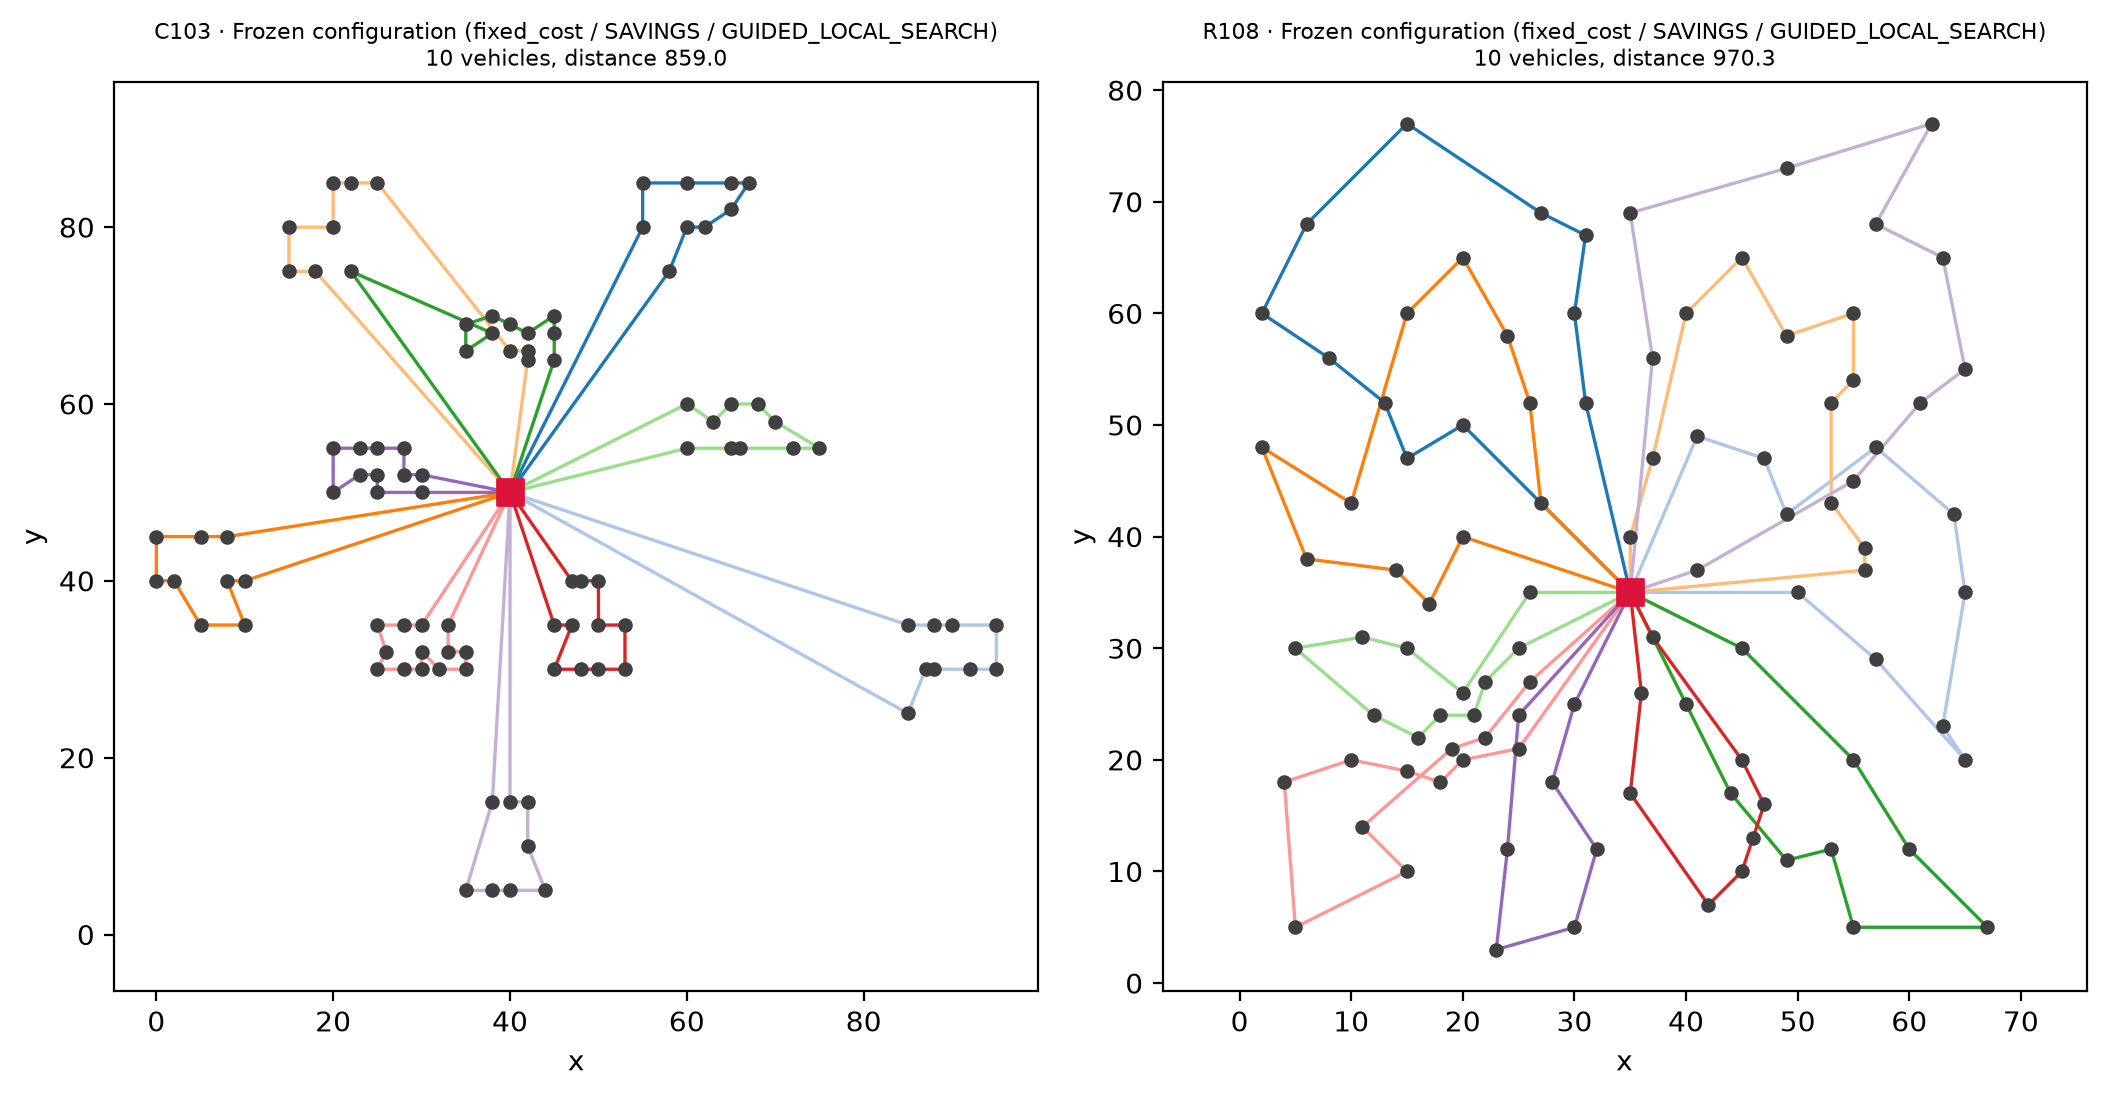

In [6]:
viz_results.plot_route_panels(analysis.frozen_panels(["C103", "R108"], instances, grid, config, LANG), LANG)
plt.show()

**Insight.** On C103 the frozen solution uses 10 vehicles and distance 859.0 (reference: 10 and 828.06); on R108, 10 vehicles and 970.3 (reference: 9 and 960.88). Visually, on C103 each route serves one or a few compact clusters and routes hardly cross; on R108 the routes form elongated sectors from the depot, with some overlap. The maps illustrate two instances and prove nothing about the others; the one-vehicle difference on R108 already shows in the vehicle count. **Limitations:** qualitative reading of two instances; route colours carry no meaning. **Next decision:** record the limitations of the grid.

## 7. Sensitivity to the time budget

**Question:** does more search time close the extra vehicle relative to SINTEF? **What will be done:** the frozen configuration (`fixed_cost` + `SAVINGS` + `GUIDED_LOCAL_SEARCH`) was run on the same 14 development instances with budgets of 10, 30, 60, 120 and 300 s (one run per instance and budget, 70 in total, all verified in double precision). This study was carried out after the tournament, took no part in choosing the configuration and was used to decide the evaluation budget, a decision made before the evaluation instances were opened (`reports/protocolo-avaliacao.md`). **What the table shows:** per budget, the mean Δ vehicles against SINTEF, on how many instances the fleet equals the reference, the median distance gap among those instances only, and the mean runtime.

In [7]:
time_df = results.load_time_sensitivity(R["time_sensitivity"], split)
curve = analysis.time_curve_table(time_df)

display(eda.localize_columns(analysis.time_curve_table_display(curve), LANG))

,Time budget (s),No. of instances,Mean Δ vehicles,Instances with fleet equal to reference,"Median gap, equal fleet (%)",Mean runtime (s)
0,10,14,1.00,5,1.53,10.0
1,30,14,0.86,5,1.53,30.0
2,60,14,0.79,6,1.64,60.0
3,120,14,0.64,7,1.74,120.0
4,300,14,0.64,7,1.16,300.0


**Insight.** The mean Δ vehicles falls from 1.00 (10 s) to 0.86 (30 s), 0.79 (60 s) and 0.64 (120 s), and stays at 0.64 with 300 s. Instances with a fleet equal to SINTEF's go from 5 of 14 (10 s and 30 s) to 6 (60 s) and 7 (120 s and 300 s). The mean runtime equals the budget in every case (10.0 to 300.0 s), that is, the whole budget was used. The median gap among the equal-fleet instances varies little (1.53%, 1.53%, 1.64%, 1.74% and 1.16%), but the set of instances changes between rows, so these values are not comparable with each other. **Limitation:** there is one run per instance and budget, and identical runs can differ by ±1 vehicle on the R and RC families because of the wall clock; the curve is an aggregate trend, not per-instance evidence. **Next decision:** see on which instances the fleet changes.

**Question:** which instances account for the gain? **What will be shown:** the table lists vehicles per instance and budget, with the SINTEF reference; plot (a) repeats the mean Δ against the budget on a logarithmic scale and plot (b) draws one line per R and RC instance, with the SINTEF fleet as a dashed level.

,Instance,Family,SINTEF vehicles,10 s,30 s,60 s,120 s,300 s
0,C103,C1,10,10,10,10,10,10
1,C106,C1,10,10,10,10,10,10
2,C203,C2,3,3,3,3,3,3
3,C206,C2,3,3,3,3,3,3
4,R108,R1,9,10,10,10,10,10
5,R110,R1,10,12,12,12,12,12
6,R111,R1,10,12,11,11,11,11
7,R201,R2,4,4,4,4,4,4
8,R202,R2,3,4,4,4,4,4
9,R207,R2,2,3,3,3,3,3


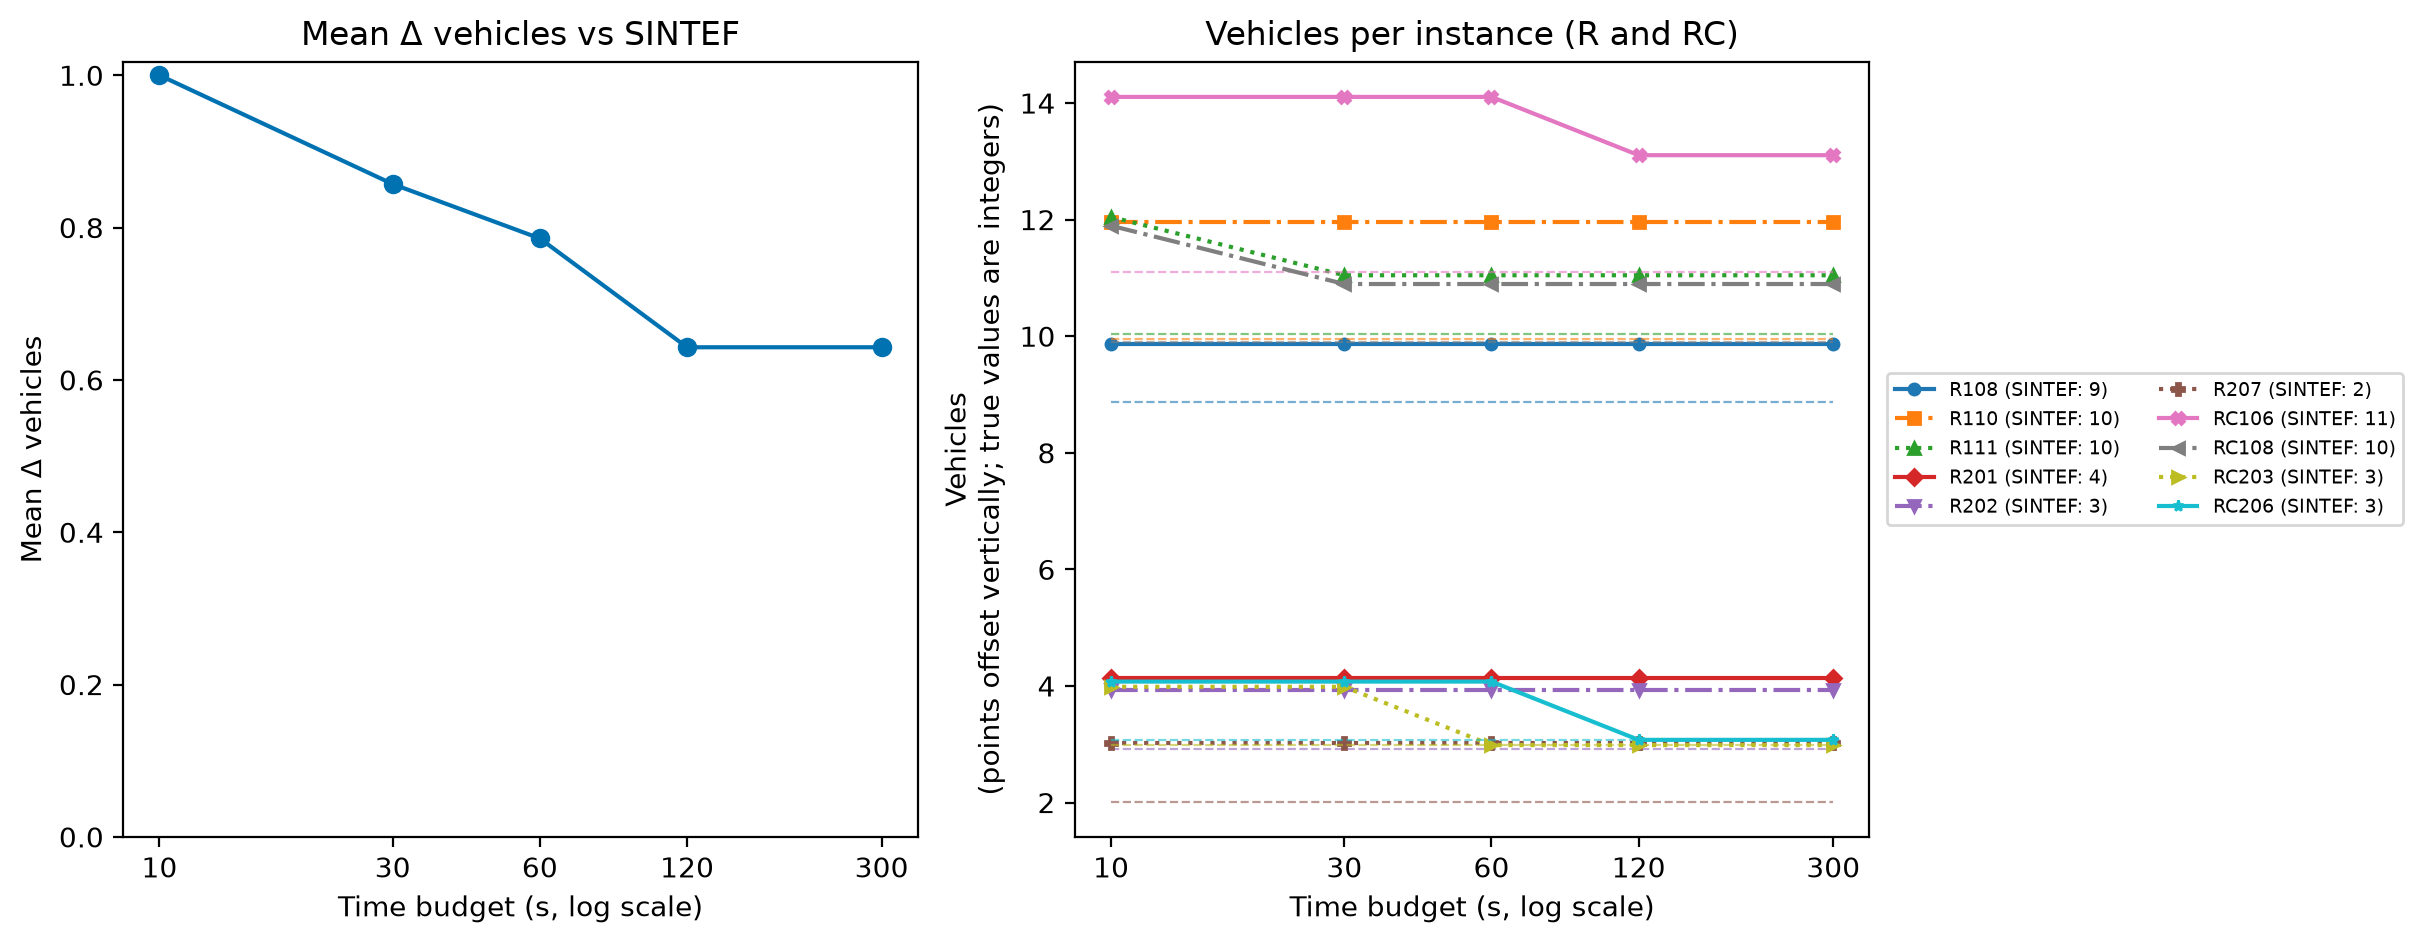

In [8]:
display(eda.localize_columns(analysis.time_curve_by_instance(time_df), LANG))

viz_results.plot_time_curve(time_df, LANG)
plt.show()

**Insight.** The R1 and R2 instances do not change fleet between 30 s and 300 s (R108 at 10, R110 at 12, R202 at 4 and R207 at 3 vehicles in every budget; R201 stays at 4); the only change among the R instances is R111, from 12 to 11 vehicles between 10 s and 30 s. The remaining gains appear in the RC families: RC108 goes from 12 to 11 between 10 s and 30 s, RC203 from 4 to 3 with 60 s, RC106 from 14 to 13 and RC206 from 4 to 3 with 120 s. The C families keep the SINTEF fleet in every budget. With 300 s, 9 vehicles above the reference remain, summed over the 7 R and RC instances whose fleet is still larger (R108, R110, R111, R202, R207, RC106 and RC108). Where the fleet is equal, the gap of R201 goes from 4.71% (10 s) to 1.16% (300 s) and that of C203 reaches 0.00% with 300 s; RC203 and RC206 match the fleet with gaps of 7.2% and 10.6%. **Limitation:** these are changes of 1 vehicle in a single run, the same size as the wall-clock variability; no cause is claimed for them. **Next decision:** handle the variability with replicates in the evaluation.

## 8. Audited limitations

**Question:** which limitations of the grid can be quantified from the file itself? **What the tables show:** the first has (i) how many `reduce_fleet` cells had the first fleet reduction without a solution (`attempts` field: second attempt infeasible); (ii) the mean runtime of `TABU_SEARCH` and how many of those cells ended before 29 s of the 30 s budget; (iii) the mean runtime of `GUIDED_LOCAL_SEARCH`; (iv) the maximum number of replicates per cell. The second table shows **how long the `reduce_fleet` cells really ran**, per first solution: cells, minimum, median and maximum runtime, how many ended within 1 s after the first 10 s step (that is, the second attempt, with one vehicle fewer, failed in under 1 s), how many used the whole 5 s step of the second attempt, and the share of the 30 s budget used (median).

In [9]:
display(eda.localize_columns(analysis.limitations_table(grid, LANG), LANG))
display(eda.localize_columns(analysis.reduce_fleet_timing(grid), LANG))

,Indicator,Value
0,Cells with the reduce_fleet strategy,126
1,Cells where the first fleet reduction found no...,126 / 126
2,Mean runtime of reduce_fleet cells (s),11.8
3,fixed_cost cells with TABU_SEARCH,42
4,"Of which, stopped before 29 s",12 / 42
5,Mean runtime of TABU_SEARCH under fixed_cost (s),25.4
6,Mean runtime of GUIDED_LOCAL_SEARCH under fixe...,30.0
7,Replicates per cell (maximum),1


,First solution,Cells,Minimum runtime (s),Median runtime (s),Longest runtime (s),Cells with runtime < first step + 1 s,Cells in which the 2nd attempt used its whole step,"Budget used, median (%)"
0,PARALLEL_CHEAPEST_INSERTION,42,10.07,10.14,10.28,42,0,33.8
1,PATH_CHEAPEST_ARC,42,6.42,15.01,15.04,2,40,50.0
2,SAVINGS,42,1.08,10.47,12.10,28,0,34.9


**Insight.** Of the 126 `reduce_fleet` cells, in all 126 the first attempt to reduce the fleet (one vehicle fewer than the initial solution) found no solution and the loop stopped. The runtimes show that the cause was **not** the 5 s step being too short, as was previously stated (the earlier statement was wrong): with `PARALLEL_CHEAPEST_INSERTION`, the 42 cells took 10.07 to 10.28 s (median 10.14 s), that is, less than 1 s beyond the first 10 s step; with `SAVINGS`, the median was 10.47 s (1.08 to 12.10 s) and 28 of 42 cells ended less than 1 s beyond the first step. The second attempt therefore failed almost at once, which is consistent with a failure in the construction of the solution: the model does not allow dropping customers and the search starts from scratch with the smaller fleet. The rest of the 30 s budget was discarded by the `break` (median budget used: 33.8% with `PARALLEL_CHEAPEST_INSERTION` and 34.9% with `SAVINGS`); in practice, `reduce_fleet` competed with about 10 s against the 30 s of `fixed_cost`. Only `PATH_CHEAPEST_ARC` (median 15.01 s; 40 of 42 cells) spent the whole 5 s step on the second attempt; in that case the time limit cannot be ruled out as a cause, and a longer step was not tested. The 1.08 s cell (C106, `SAVINGS`, `TABU_SEARCH`) has `attempts` = [[25, true, 10, 828.94], [9, false]]: the first solve ended early (the same configuration with `fixed_cost` ended in 0.95 s, with the same fleet and distance, and `TABU_SEARCH` stopped before 29 s in 12 of the 42 `fixed_cost` cells) and the second attempt then failed; why `TABU_SEARCH` stops early was not investigated. The `fixed_cost` × `reduce_fleet` comparison in this tournament is therefore inconclusive and biased against `reduce_fleet` (less effective time, construction without dropping, no warm start); fixing it requires a warm start from the previous solution and penalised dropping, carried out later as experiment B3 of the sanity plan (`reports/plano-sanidade-auditoria.md`; section 9). `TABU_SEARCH` under `fixed_cost` ended before 29 s in 12 of 42 cells (mean 25.4 s), whereas `GUIDED_LOCAL_SEARCH` used the whole budget (30.0 s on average). The maximum number of replicates per cell is 1, so wall-clock variability was not measured in the grid (section 7 shows, in the budget study, that runs with the same configuration can differ). **Consequence for the reading:** choosing by mean rank is valid as a pre-registered rule, but the `reduce_fleet` positions mainly reflect the first solution obtained in about 10 s, and small differences among the top positions are not evidence of superiority.

## 9. v2 diagnostics (Phase B)

After the final evaluation, an external audit raised hypotheses about the solver (`reports/plano-sanidade-auditoria.md`). The **v2** protocol (`reports/protocolo-v2.md`) was registered **before** any run and uses **only the 14 development instances**: the frozen v1 configuration as the base, 120 s per run, 3 replicates per cell, 8 processes, machine with no other load. The result per instance is the lexicographic representative replicate (defined in this project; 2nd of 3, ordering by feasibility, vehicles and distance), and the levels are compared by the **same rule as the tournament** (mean rank; ties broken by the mean Δ vehicles and by the median gap with equal fleet). The frozen results are in `outputs/frozen/v2/`. The v1 is not changed: experiments B1 to B4 ask whether a different integer scale, fixed cost, fleet strategy or machine load would change the configuration; B5 (warm start in layer B) is in notebook 06.

**Question:** are blocks B1 to B4 complete and feasible, and what did each decide under the pre-registered rule? **What the table shows:** the coverage of the four blocks (cells, instances, feasibility in the double-precision verifier, processes and mean runtime) and, for B1 to B3, the levels ordered by mean rank, the chosen level and the step of the rule that decided (read from `decision.json`).

In [10]:
blocks = {name: results.load_v2_block(R[f"v2_{name}"], split) for name in ("B1", "B2", "B3", "B4")}
decisions = {name: results.load_v2_decision(R[f"v2_{name}_decision"], split) for name in ("B1", "B2", "B3")}

display(eda.localize_columns(v2_view.block_coverage(blocks, LANG), LANG))
display(eda.localize_columns(v2_view.decision_table(decisions, LANG), LANG))

,Block,Cells,No. of instances,Feasible,Processes,Mean runtime (s)
0,B1 · integer scale,84,14,84,8,120.0
1,B2 · fixed cost per vehicle,84,14,84,8,120.0
2,B3 · fleet strategy,42,14,42,8,112.9
3,B4 · machine load (4 processes),42,14,42,4,120.0


,Block,"Levels (mean rank, best first)",Chosen level,Rule that decided
0,B1 · integer scale,scale 10000: 1.32 · scale 100: 1.68,scale 10000,mean rank
1,B2 · fixed cost per vehicle,k = 10: 1.89 · k = 100: 1.96 · k = 1: 2.14,k = 10,mean rank
2,B3 · fleet strategy,fixed_cost: 1.32 · reduce_fleet_v2: 1.68,fixed_cost,not strictly better



**Insight.** The four blocks are complete and feasible: B1 has 84 cells (2 scales × 14 instances × 3 replicates), B2 has 84 (k = 1 and k = 100), B3 has 42 (`reduce_fleet` v2) and B4 has 42 (4 processes); all are feasible in the double-precision verifier and all belong to development instances. The mean runtime is 120.0 s per run, except in B3 (112.9 s, below the budget; the cause was not investigated). Under the pre-registered rule: B1 chooses scale 10 000 (mean rank 1.32 against 1.68 for scale 100); B2 keeps k = 10 (1.89, against 1.96 for k = 100 and 2.14 for k = 1); B3 keeps `fixed_cost` (1.32), because `reduce_fleet` v2 (1.68) is not strictly better. **Limitations:** the mean ranks use the representative replicate of only 3 per cell and 14 instances, so small differences may be within wall-clock noise; the per-instance tables that follow show what is behind each decision. **Next decision:** read the blocks one by one, starting with the scale.


**B1 — integer scale.** **Question:** does scale 100 (v1) prune valid routes, and does scale 10 000 change the fleet? **What is shown:** the ranking of the two levels; the per-instance table with the representative replicate (vehicles and distance) at each scale next to the SINTEF fleet; the instances where the two levels differ in fleet or in distance by 1% or more (the distance change is only defined with equal fleets); the aggregate comparison; and the vehicles of each replicate of R110, the instance where scale 100 was shown to prune a valid route.

In [11]:
rows_b1, level_b1 = v2_view.compared_rows("B1", blocks)

display(eda.localize_columns(v2_view.ranking_display(results.load_ranking(R["v2_B1_ranking"]), level_b1, LANG), LANG))
display(eda.localize_columns(v2_view.level_by_instance(rows_b1, level_b1, LANG), LANG))
display(eda.localize_columns(v2_view.pairwise_instances(rows_b1, level_b1, 100, 10000, LANG), LANG))
display(eda.localize_columns(v2_view.level_comparison(rows_b1, level_b1, 100, LANG), LANG))
display(eda.localize_columns(v2_view.replicates_table(rows_b1, "R110", level_b1, LANG), LANG))

,Position,Integer scale,Mean rank,Mean Δ vehicles,Instances with fleet equal to reference,"Median gap, equal fleet (%)",Mean runtime (s)
0,1,scale 10000,1.321,0.571,7,1.216,120.0
1,2,scale 100,1.679,0.643,7,1.529,120.0


,Instance,SINTEF vehicles,Vehicles (scale 100),Distance (scale 100),Vehicles (scale 10000),Distance (scale 10000)
0,C103,10,10,859.0,10,858.1
1,C106,10,10,828.9,10,828.9
2,C203,3,3,600.2,3,594.8
3,C206,3,3,588.5,3,588.5
4,R108,9,10,970.3,10,972.6
5,R110,10,12,1102.8,11,1113.9
6,R111,10,11,1070.3,11,1075.6
7,R201,4,4,1267.6,4,1267.6
8,R202,3,4,1114.6,4,1096.2
9,R207,2,3,830.5,3,823.9


,Instance,SINTEF vehicles,Vehicles (base),Vehicles (compared),Distance (base),Distance (compared),Distance change (%)
0,R110,10,12,11,1102.8,1113.9,NaN
1,R202,3,4,4,1114.6,1096.2,-1.7
2,RC203,3,3,3,1125.2,1101.8,-2.1
3,RC206,3,3,3,1268.2,1225.2,-3.4


,Level,No. of instances,Instances with fewer vehicles,Instances with more vehicles,Instances with equal fleet,"Distance change, mean (%)","Distance change, median (%)"
0,scale 10000 / scale 100,14,1,0,13,-0.62,-0.1


,Level,Vehicles per replicate,Vehicles,SINTEF vehicles
0,scale 100,12 · 12 · 12,12,10
1,scale 10000,11 · 11 · 11,11,10



**Insight.** With scale 10 000, the mean rank is 1.32 against 1.68 for scale 100; the mean Δ vehicles against SINTEF is 0.57 against 0.64, the fleet equals SINTEF's in 7 instances at both levels, and the median gap with equal fleet is 1.22% against 1.53%. The fleet changes in one instance: R110 goes from 12 to 11 vehicles in all 3 replicates (12 · 12 · 12 against 11 · 11 · 11), which confirms, for that instance, the audit's finding that scale 100 prunes valid routes; R110 remains 1 vehicle above SINTEF (10). In the other 13 instances the fleet is the same and the distance change is −0.62% on average and −0.10% at the median; among those that move by 1% or more, R202 (−1.7%), RC203 (−2.1%) and RC206 (−3.4%) get shorter. Under the pre-registered rule, scale 10 000 wins on mean rank alone, with no tie-break. **Limitations:** there are 14 instances and 3 replicates per cell; distance changes of 1% to 3% are as large as the run-to-run variability seen in the evaluation (up to 3.2% between replicates), so no single instance proves an effect of the scale on distance; only R110 has an effect on the fleet. **Next decision:** check the fixed cost per vehicle (B2).


**B2 — fixed cost per vehicle.** **Question:** does a smaller or larger relative fixed cost (k = 1, 10 or 100, at the scale chosen in B1) change the fleet or the distance? The audit's hypothesis was that a very high fixed cost would distort `GUIDED_LOCAL_SEARCH` and hinder fleet reduction. **What is shown:** the ranking of the three levels (k = 10 comes from B1 and was not re-run), the per-instance table, and the comparison of k = 1 and k = 100 against k = 10: instances with fewer, equal or more vehicles and the distance change on the equal-fleet ones.

In [12]:
rows_b2, level_b2 = v2_view.compared_rows("B2", blocks)

display(eda.localize_columns(v2_view.ranking_display(results.load_ranking(R["v2_B2_ranking"]), level_b2, LANG), LANG))
display(eda.localize_columns(v2_view.level_by_instance(rows_b2, level_b2, LANG), LANG))
display(eda.localize_columns(v2_view.level_comparison(rows_b2, level_b2, 10.0, LANG), LANG))

,Position,Relative fixed cost (k),Mean rank,Mean Δ vehicles,Instances with fleet equal to reference,"Median gap, equal fleet (%)",Mean runtime (s)
0,1,k = 10,1.893,0.571,7,1.216,120.0
1,2,k = 100,1.964,0.571,7,1.216,120.0
2,3,k = 1,2.143,0.571,7,1.529,120.0


,Instance,SINTEF vehicles,Vehicles (k = 1),Distance (k = 1),Vehicles (k = 10),Distance (k = 10),Vehicles (k = 100),Distance (k = 100)
0,C103,10,10,858.1,10,858.1,10,858.1
1,C106,10,10,828.9,10,828.9,10,828.9
2,C203,3,3,600.2,3,594.8,3,594.8
3,C206,3,3,588.5,3,588.5,3,588.5
4,R108,9,10,972.6,10,972.6,10,972.6
5,R110,10,11,1113.9,11,1113.9,11,1113.9
6,R111,10,11,1081.2,11,1075.6,11,1078.2
7,R201,4,4,1267.6,4,1267.6,4,1267.6
8,R202,3,4,1096.2,4,1096.2,4,1096.2
9,R207,2,3,823.9,3,823.9,3,823.9


,Level,No. of instances,Instances with fewer vehicles,Instances with more vehicles,Instances with equal fleet,"Distance change, mean (%)","Distance change, median (%)"
0,k = 1 / k = 10,14,0,0,14,0.10,0.0
1,k = 100 / k = 10,14,0,0,14,0.02,0.0



**Insight.** The three levels give the same fleet in all 14 instances: relative to k = 10, both k = 1 and k = 100 have 0 instances with fewer vehicles, 0 with more and 14 with an equal fleet. The distance changes little: +0.10% on average with k = 1 and +0.02% with k = 100, with a median of 0.0% in both. The mean ranks are 1.89 (k = 10), 1.96 (k = 100) and 2.14 (k = 1), and k = 1 is the only one with a worse median gap (1.53% against 1.22%). Under the rule, k = 10 is kept because it has the lowest mean rank. The hypothesis that a high fixed cost would hinder fleet reduction **was not confirmed**: lowering the fixed cost to k = 1 did not reduce vehicles in any instance and only worsened the distance. **Limitations:** the 0.07 difference in rank between k = 10 and k = 100 is small given 3 replicates per cell, and the comparison covers only three levels at one scale; the effect of the fixed cost on the trajectory of `GUIDED_LOCAL_SEARCH` was not examined. **Next decision:** compare the fleet strategies (B3).


**B3 — fleet strategy.** **Question:** does the corrected fleet reduction (`reduce_fleet` v2: warm start from the best plan, an emptied route, penalised dropping only during the reduction, total budget of 120 s) beat `fixed_cost`? The pre-registered rule requires it to be **strictly better** in mean rank to replace `fixed_cost`. **What is shown:** the ranking, the per-instance table, the comparison against `fixed_cost`, and the instances where the two strategies differ in fleet or in distance by 1% or more.

In [13]:
rows_b3, level_b3 = v2_view.compared_rows("B3", blocks)

display(eda.localize_columns(v2_view.ranking_display(results.load_ranking(R["v2_B3_ranking"]), level_b3, LANG), LANG))
display(eda.localize_columns(v2_view.level_by_instance(rows_b3, level_b3, LANG), LANG))
display(eda.localize_columns(v2_view.level_comparison(rows_b3, level_b3, "fixed_cost", LANG), LANG))
display(eda.localize_columns(v2_view.pairwise_instances(rows_b3, level_b3, "fixed_cost", "reduce_fleet_v2", LANG), LANG))

,Position,Fleet strategy,Mean rank,Mean Δ vehicles,Instances with fleet equal to reference,"Median gap, equal fleet (%)",Mean runtime (s)
0,1,fixed_cost,1.321,0.571,7,1.216,120.0
1,2,reduce_fleet_v2,1.679,0.500,8,1.852,112.9


,Instance,SINTEF vehicles,Vehicles (fixed_cost),Distance (fixed_cost),Vehicles (reduce_fleet_v2),Distance (reduce_fleet_v2)
0,C103,10,10,858.1,10,858.1
1,C106,10,10,828.9,10,828.9
2,C203,3,3,594.8,3,600.2
3,C206,3,3,588.5,3,588.5
4,R108,9,10,972.6,10,974.9
5,R110,10,11,1113.9,11,1113.9
6,R111,10,11,1075.6,11,1108.0
7,R201,4,4,1267.6,4,1274.2
8,R202,3,4,1096.2,3,1215.1
9,R207,2,3,823.9,3,860.0


,Level,No. of instances,Instances with fewer vehicles,Instances with more vehicles,Instances with equal fleet,"Distance change, mean (%)","Distance change, median (%)"
0,reduce_fleet_v2 / fixed_cost,14,1,0,13,1.82,0.24


,Instance,SINTEF vehicles,Vehicles (base),Vehicles (compared),Distance (base),Distance (compared),Distance change (%)
0,R111,10,11,11,1075.6,1108.0,3.0
1,R202,3,4,3,1096.2,1215.1,NaN
2,R207,2,3,3,823.9,860.0,4.4
3,RC203,3,3,3,1101.8,1236.3,12.2
4,RC206,3,3,3,1225.2,1259.4,2.8



**Insight.** `fixed_cost` has a mean rank of 1.32 and `reduce_fleet` v2, 1.68 (mean Δ vehicles 0.57 against 0.50; fleet equal to SINTEF's in 7 against 8 instances; median gap 1.22% against 1.85%; mean runtime 120.0 s against 112.9 s). In fleet, `reduce_fleet` v2 improves one instance: R202 goes from 4 to 3 vehicles and matches SINTEF; in the other 13 the fleet is the same. In distance, with equal fleets, it is worse by 1.82% on average (median 0.24%), with worsenings of 12.2% in RC203, 4.4% in R207, 3.0% in R111 and 2.8% in RC206, with no vehicle gain in those instances. Because the mean rank of `reduce_fleet` v2 is not strictly lower, the rule keeps `fixed_cost`. R1 and RC1 remain +1 to +2 vehicles above SINTEF under both strategies (R108, R110, R111, RC106 and RC108). **Limitations:** only R202 gains fleet; the time spent on failed reduction attempts is not available to improve the distance, which is consistent with the distance worsenings, but that cause was not tested; there are 3 replicates per cell. **Next decision:** check whether the machine load changes the result (B4).


**B4 — machine load.** **Question:** does running with 4 processes instead of 8 (less risk of thermal throttling or CPU contention) change the fleet or the distance? **What the table shows:** the same configuration (`fixed_cost`, scale 10 000, k = 10, 120 s) with 4 processes, compared cell by cell (instance × replicate) with the 8-process one from B1: cells with a different fleet and with a different distance, and the distance of the representative replicate in both cases. There is no automatic decision: if the fleet changed, the v2 evaluation would use 4 processes.

In [14]:
display(eda.localize_columns(v2_view.workers_by_instance(blocks["B4"], blocks["B1"], LANG), LANG))

,Instance,Cells,Cells with different fleet,Cells with different distance,"Distance, 8 processes","Distance, 4 processes",Distance change (%)
0,C103,3,0,0,858.1,858.1,0.00
1,C106,3,0,0,828.9,828.9,0.00
2,C203,3,0,3,594.8,591.2,-0.62
3,C206,3,0,0,588.5,588.5,0.00
4,R108,3,0,0,972.6,972.6,0.00
5,R110,3,0,0,1113.9,1113.9,0.00
6,R111,3,0,3,1075.6,1078.2,0.24
7,R201,3,0,0,1267.6,1267.6,0.00
8,R202,3,0,0,1096.2,1096.2,0.00
9,R207,3,0,0,823.9,823.9,0.00



**Insight.** The fleet is the same in all 42 cells (14 instances × 3 replicates) with 4 and with 8 processes. The distance differs in 9 of the 42 cells, all in three instances (C203, R111 and RC106, 3 cells each). In the representative replicate, the distance change with 4 processes is −0.62% in C203 (591.2 against 594.8), +0.24% in R111 and +0.99% in RC106, that is, in both directions. The machine load therefore did not change the fleet and affected the distance in 3 of the 14 instances, in both directions; under the B4 rule, the v2 evaluation uses 8 processes. **Limitations:** the comparison is cell by cell (instance × replicate), and replicates already differ from one another by wall clock, so the 3 instances with a difference may reflect run-to-run variability rather than the load; there are 14 development instances and the experiment does not measure the effect of a genuinely busy machine. **Next decision:** the v2 configuration is the v1 one with scale 10 000 and relative fixed cost k = 10, whose magnitude is about 50% to 66% of the absolute fixed cost of the v1 (notebook 05, section 11); warm start in layer B (B5) is in notebook 06.


## 10. Synthesis and next steps

- The configuration `fixed_cost` + `SAVINGS` + `GUIDED_LOCAL_SEARCH` was frozen by the pre-registered rule, using only the 14 development instances: mean rank 5.607 out of 18, mean Δ vehicles 0.86 and a fleet equal to SINTEF's on 5 of the 14 instances.
- Local search is the most visible factor: it lowers the mean Δ of the three constructions from 1.86 to 8.36 down to 0.86 to 1.00. Among the metaheuristics, `SIMULATED_ANNEALING` took the worst positions; the first-over-second margin is small and was measured with one replicate per cell.
- `reduce_fleet` was not effectively tested: in 126 of 126 cells the reduction to one vehicle fewer failed almost at once (median runtime 10.1 to 15.0 s of the 30 s; section 8), the rest of the budget was discarded and the comparison is inconclusive and biased against the strategy; `TABU_SEARCH` ended before the budget in 12 of 42 cells. Experiment B3 (section 9) redid the comparison with the corrected fleet reduction (warm start, penalised dropping, 120 s): `reduce_fleet` v2 matches SINTEF in R202 (4 → 3 vehicles), but has a worse mean rank (1.68 against 1.32) and worsens the distance in several instances; the pre-registered rule keeps `fixed_cost`.
- Sensitivity to the time budget (section 7) shows a mean Δ vehicles of 1.00 (10 s), 0.86 (30 s), 0.79 (60 s) and 0.64 (120 s and 300 s), with a fleet equal to SINTEF's on 5, 5, 6, 7 and 7 of the 14 instances; the gains between 30 s and 300 s come from the RC families and the R1 and R2 families do not change fleet between 30 s and 300 s. This study was done after the tournament and informed the evaluation budget.
- Identical runs (same instance, configuration and budget) do not always give the same solution, because the solver stops by the wall clock: on the R and RC families, ±1 vehicle is possible between runs, and differences of that size in a single run are not evidence.
- **v2 configuration (Phase B, section 9):** v2 = the v1 configuration with integer scale 10 000 and relative fixed cost k = 10, whose magnitude is about 50% to 66% of the absolute fixed cost of the v1 (notebook 05, section 11), so it differs from the v1 in two respects (B1 isolates the scale, with k = 10 at both levels: R110 goes from 12 to 11 vehicles; B2: the fleet is the same at the three k levels, which suggests, but does not prove, that the magnitude of the fixed cost was not what changed the fleet), `fixed_cost` as the fleet strategy (B3: `reduce_fleet` v2 matches SINTEF in R202, but is not strictly better) and 8 processes (B4: the fleet did not change with 4). The v1 remains the original result; the v2 was applied to the evaluation instances only post hoc (notebook 05, section 11).

**Next steps:** (i) the evaluation uses 120 s per run and 5 replicates per instance, with the median replicate as the main result and the range across replicates reported separately (pre-registered in `reports/protocolo-avaliacao.md`, before the evaluation instances were opened); (ii) the frozen configuration will be run, with independent double-precision verification, on the 42 evaluation instances, reporting Δ vehicles and distance gap in separate columns and the latter only where the fleet equals the reference. SINTEF values are best known, not proven optimal. The post-hoc v2 re-evaluation (Phase D) was done later, by a separately recorded decision, and is shown beside the v1 in notebook 05 without replacing it.

## References

- Barr, R. S., Golden, B. L., Kelly, J. P., Resende, M. G. C., & Stewart, W. R. (1995). Designing and reporting on computational experiments with heuristic methods. *Journal of Heuristics, 1*(1), 9–32.
- Bräysy, O., & Gendreau, M. (2005b). Vehicle routing problem with time windows, Part II: Metaheuristics. *Transportation Science, 39*(1), 119–139.
- Clarke, G., & Wright, J. W. (1964). Scheduling of vehicles from a central depot to a number of delivery points. *Operations Research, 12*(4), 568–581.
- Glover, F. (1986). Future paths for integer programming and links to artificial intelligence. *Computers & Operations Research, 13*(5), 533–549.
- Kaufman, S., Rosset, S., Perlich, C., & Stitelman, O. (2012). Leakage in data mining: Formulation, detection, and avoidance. *ACM Transactions on Knowledge Discovery from Data, 6*(4), Article 15.
- Kirkpatrick, S., Gelatt, C. D., & Vecchi, M. P. (1983). Optimization by simulated annealing. *Science, 220*(4598), 671–680.
- Nosek, B. A., Ebersole, C. R., DeHaven, A. C., & Mellor, D. T. (2018). The preregistration revolution. *Proceedings of the National Academy of Sciences, 115*(11), 2600–2606.
- Perron, L., & Furnon, V. (2026). *OR-Tools* (Version 9.15) [Computer software]. Google. https://developers.google.com/optimization/
- SINTEF. (2008). *VRPTW — 100 customers: Solomon benchmark, best known solutions*. SINTEF TOP. https://www.sintef.no/projectweb/top/vrptw/100-customers/
- Voudouris, C., & Tsang, E. (1999). Guided local search and its application to the traveling salesman problem. *European Journal of Operational Research, 113*(2), 469–499.